<a href="https://colab.research.google.com/github/mdd214/CDS230-Lab8/blob/main/Lab8_KNN_Pima.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Moon Sungil, Hyunwoo Sun

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

columns = ['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness',
           'Insulin', 'BMI', 'DiabetesPedigree', 'Age', 'Outcome']
df = pd.read_csv('pima-indians-diabetes.csv', header=None, names=columns)

print(df.shape)                      # (768, 9)
print(df['Outcome'].value_counts())  # 0 = no diabetes, 1 = diabetes
df.head()

(768, 9)
Outcome
0    500
1    268
Name: count, dtype: int64


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigree,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [3]:
X = df.drop('Outcome', axis=1)
y = df['Outcome']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)   # fit only on training data
X_test_scaled  = scaler.transform(X_test)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 614
Testing samples: 154


Accuracy: 0.7012987012987013
              precision    recall  f1-score   support

 No Diabetes       0.75      0.80      0.78       100
    Diabetes       0.58      0.52      0.55        54

    accuracy                           0.70       154
   macro avg       0.67      0.66      0.66       154
weighted avg       0.69      0.70      0.70       154



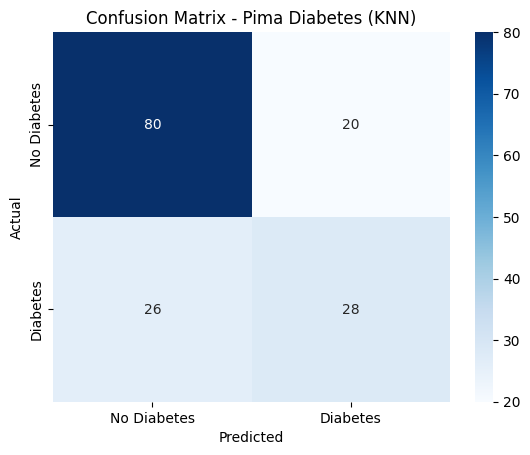

In [4]:
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train_scaled, y_train)
y_pred = knn.predict(X_test_scaled)

print("Accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred, target_names=['No Diabetes', 'Diabetes']))

cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['No Diabetes', 'Diabetes'],
            yticklabels=['No Diabetes', 'Diabetes'])
plt.xlabel('Predicted'); plt.ylabel('Actual')
plt.title('Confusion Matrix - Pima Diabetes (KNN)')
plt.show()

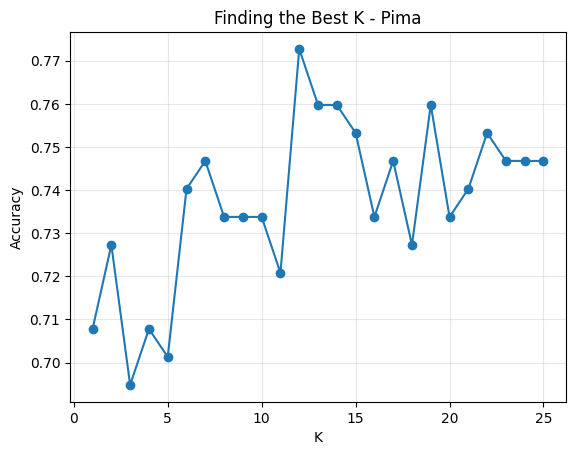

Best K: 12  Accuracy: 0.7727272727272727


In [5]:
k_values = range(1, 26)
accuracies = []
for k in k_values:
    model = KNeighborsClassifier(n_neighbors=k)
    model.fit(X_train_scaled, y_train)
    accuracies.append(accuracy_score(y_test, model.predict(X_test_scaled)))

plt.plot(k_values, accuracies, marker='o')
plt.xlabel('K'); plt.ylabel('Accuracy'); plt.title('Finding the Best K - Pima')
plt.grid(alpha=0.3); plt.show()

best_k = list(k_values)[np.argmax(accuracies)]
print("Best K:", best_k, " Accuracy:", max(accuracies))

In [6]:
final_model = KNeighborsClassifier(n_neighbors=best_k)
final_model.fit(X_train_scaled, y_train)

new_person = pd.DataFrame({'Pregnancies': [2], 'Glucose': [150], 'BloodPressure': [70],
                           'SkinThickness': [30], 'Insulin': [100], 'BMI': [35.0],
                           'DiabetesPedigree': [0.5], 'Age': [45]})
new_scaled = scaler.transform(new_person)
print("Prediction (1 = diabetes):", final_model.predict(new_scaled)[0])
print("Probability [no, yes]:", final_model.predict_proba(new_scaled)[0])

Prediction (1 = diabetes): 1
Probability [no, yes]: [0.41666667 0.58333333]


## Summary

This project uses data from 768 women. The data shows 8 health measurements of each woman. There are 2 groups: diabetes and no diabetes.

KNN looks at the most similar women and copies their answer. The model was right 70% of the time with K=5, and 77% with K=12.

The model finds women without diabetes well. It misses about half of the women with diabetes.

Dataset Source

Kaggle – Pima Indians Diabetes (CSV)

https://www.kaggle.com/datasets/kumargh/pimaindiansdiabetescsv